# 1. CERT r6.2: data preparation and exploratory analysis

This notebook prepares the CERT r6.2 source files for the research pipeline. It checks the activity records, combines the monthly organisational snapshots and saves the working tables used by the later notebooks.

**Inputs:** the extracted CERT r6.2 dataset and its answer files in the Kaggle folder specified in the setup cell. This version uses the extracted folder layout, so no ZIP extraction is needed.

Logon, device, file and email records are converted to Parquet. Email message content is not loaded. The much larger HTTP file is read in chunks and reduced to daily counts, after-hours activity and distinct-domain counts. Notebook 2 reads these summaries from `http_daily.parquet`.

The answer files are loaded before the HTTP processing so that activity from the designated insider accounts can be retained for the timeline figures. These descriptive extracts are separate from the common technical features.

**Outputs:** prepared activity tables, organisational snapshots, answer-file extracts, summary tables and exploratory figures. The final section lists the files and their uses.

Read the cells from top to bottom. Notebook 2 constructs the as-run user-day labels; Notebook 5c examines the later account-attribution correction.

*Documentation copy, 8 November 2026. Notes edited for clarity; code, saved outputs and execution metadata are unchanged. This copy has not been rerun.*


In [1]:
# ============================================================
# 0. Setup — reproducibility and confirmed paths
# ============================================================
import os, glob, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

BASE    = "/kaggle/input/datasets/thandondhlovu10/cert-r62-raw"
CSV_DIR = f"{BASE}/Data Files r6.2/Data Files r6.2/r6.2"
ANS_DIR = f"{BASE}/answers/answers"
WORK    = "/kaggle/working"
FIG_DIR = f"{WORK}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

DATE_FMT = "%m/%d/%Y %H:%M:%S"
AH_START, AH_END = 7, 18   # provisional after-hours boundary (context-aware version in NB3)

print("Activity CSVs:")
for f in sorted(os.listdir(CSV_DIR)):
    p = os.path.join(CSV_DIR, f)
    if os.path.isfile(p):
        print(f"   {f:22s} {os.path.getsize(p)/1e6:12,.1f} MB")
print("LDAP snapshots:", len(glob.glob(f"{CSV_DIR}/LDAP/*.csv")))
print("Answer key present:", os.path.exists(f"{ANS_DIR}/insiders.csv"))


Activity CSVs:
   decoy_file.csv                  1.1 MB
   device.csv                    139.5 MB
   email.csv                   8,084.8 MB
   file.csv                    1,331.3 MB
   http.csv                   90,233.4 MB
   license-exactdata.txt           0.0 MB
   license-wikipedia.txt           0.2 MB
   logon.csv                     241.6 MB
   psychometric.csv                0.2 MB
   readme.txt                      0.0 MB
LDAP snapshots: 18
Answer key present: True


## 1. Combine the monthly organisational snapshots

The Lightweight Directory Access Protocol (LDAP) snapshots provide role, functional unit, department, team and supervisor records. This cell combines the monthly files, standardises the column names and saves `ldap_monthly.parquet` for Notebook 3.

The printed summary shows the number of snapshots and the users in the first snapshot. Monthly records allow organisational changes to be tracked at that resolution; they do not establish the exact day of every change.


In [2]:
# ============================================================
# 1. LDAP snapshots
# ============================================================
frames = []
for f in sorted(glob.glob(f"{CSV_DIR}/LDAP/*.csv")):
    snap = pd.read_csv(f)
    snap["snapshot"] = os.path.basename(f).replace(".csv", "")
    frames.append(snap)
ldap = pd.concat(frames, ignore_index=True)
ldap.columns = [c.strip().lower().replace(" ", "_") for c in ldap.columns]
ldap.to_parquet(f"{WORK}/ldap_monthly.parquet", index=False)

print("LDAP columns:", ldap.columns.tolist())
print("Snapshots:", ldap['snapshot'].nunique())
print("Users in first snapshot:",
      ldap[ldap.snapshot == ldap.snapshot.min()].shape[0])
ldap.head()


LDAP columns: ['employee_name', 'user_id', 'email', 'role', 'projects', 'business_unit', 'functional_unit', 'department', 'team', 'supervisor', 'snapshot']
Snapshots: 18
Users in first snapshot: 4000


,employee_name,user_id,email,role,projects,business_unit,functional_unit,department,team,supervisor,snapshot
0,Nicholas Fletcher Pruitt,NFP2441,Nicholas.Fletcher.Pruitt@dtaa.com,ITAdmin,NaN,1,1 - Adminstration,5 - Security,8 - ElectronicSecurity,Madison Charissa Malone,2009-12
1,Abraham Dante Rodgers,ADR1517,Abraham.Dante.Rodgers@dtaa.com,ProductionLineWorker,NaN,1,5 - Manufacturing_Commercial,3 - Assembly,4 - AssemblyDept,Mark William Horne,2009-12
2,Medge Wilma Blackburn,MWB4000,Medge.Wilma.Blackburn@dtaa.com,ProductionLineWorker,NaN,1,6 - Manufacturing_Government,3 - Assembly,14 - AssemblyDept,Hillary Zenaida Adkins,2009-12
3,Meghan Laurel Salazar,MLS2856,Meghan.Laurel.Salazar@dtaa.com,ProductionLineWorker,NaN,1,6 - Manufacturing_Government,3 - Assembly,8 - AssemblyDept,Demetria Sage Melendez,2009-12
4,Beau Todd Romero,BTR2026,Beau.Todd.Romero@dtaa.com,MechanicalEngineer,NaN,1,3 - ResearchAndEngineering_Government_Domestic,4 - Engineering,16 - TestAndEvalualtion,Elijah Valentine Fuentes,2009-12


## 2. Read the answer files

This section saves `insiders.parquet` and `malicious_events.parquet`. The scenario files contain rows with different field counts, so they are parsed line by line rather than read as one rectangular table.

The date-repair check uses the scenario event dates to recover a malformed insider-window date only when the surviving date and time fragments agree. Unresolved dates stop the run.

Here, scenario events are associated with the designated insider for the descriptive timelines. Notebook 2 separately reads the original scenario files to construct account-level user-day labels. Its as-run attribution is examined later in Notebook 5c.

These answer-derived records do not become technical or context features. Labels have separate downstream uses in partition checks, validation-based selection and evaluation, so the wider workflow is not label blind.


In [3]:
# ============================================================
# 2. Answer key (labels only)
# ============================================================
insiders_all = pd.read_csv(f"{ANS_DIR}/insiders.csv")
insiders_all.columns = [c.strip().lower() for c in insiders_all.columns]
insiders = insiders_all[insiders_all["dataset"].astype(str)
                        .str.contains("6.2")].copy()
print(f"r6.2 malicious users: {len(insiders)}")
display(insiders)
# NOTE: insiders.parquet is written further down, after the malicious-event
# stream has been parsed, because the answer-key window dates are repaired
# against that stream (see "answer-key window-date repair" below).

MAL_USERS = set(insiders["user"].astype(str))

# per-scenario malicious event files (ragged rows: event types have
# different field counts, so we parse line-by-line, not with read_csv)
import csv, re
DATE_RE = re.compile(r"\d{2}/\d{2}/\d{4} \d{2}:\d{2}:\d{2}")

# map each scenario file to its insider via the 'details' column
file_to_user = dict(zip(insiders["details"].astype(str),
                        insiders["user"].astype(str)))

records = []
for f in sorted(glob.glob(f"{ANS_DIR}/r6.2-*.csv")):
    fname = os.path.basename(f)
    with open(f, newline="", encoding="utf-8", errors="replace") as fh:
        for row in csv.reader(fh):
            if not row:
                continue
            ts = next((x.strip() for x in row
                       if DATE_RE.fullmatch(x.strip())), None)
            records.append({
                "event_type": row[0].strip() if row[0] else None,
                "n_fields": len(row),
                "date": ts,
                "user": file_to_user.get(fname),
                "source_file": fname,
            })

mal_events = pd.DataFrame(records)
mal_events["date"] = pd.to_datetime(mal_events["date"], format=DATE_FMT,
                                    errors="coerce")
print("rows without a parseable timestamp:",
      mal_events["date"].isna().sum(), "of", len(mal_events))
mal_events = mal_events.dropna(subset=["date"])
mal_events.to_parquet(f"{WORK}/malicious_events.parquet", index=False)

# ------------------------------------------------------------------
# answer-key window-date repair (data-quality control, Chapter 3 §3.4)
# ------------------------------------------------------------------
# The shipped r6.2 answer key contains at least one malformed timestamp:
# CDE1846's start is "/21/2011 11:43:39" -- the month digit is absent, so
# pd.to_datetime yields NaT and that insider's malicious window silently
# disappears from every downstream artefact. The true value is recovered
# from the scenario's own malicious-event stream and accepted ONLY if every
# surviving fragment of the raw string (day, year, hour, minute, second)
# agrees with the candidate. Nothing is hard-coded, and a value that cannot
# be corroborated raises rather than passing through as NaT.
_WIN_RE = re.compile(r"^\s*(\d{1,2})?/(\d{1,2})/(\d{4})\s+(\d{2}):(\d{2}):(\d{2})\s*$")

_parsed = {c: pd.to_datetime(insiders[c], errors="coerce", format="mixed")
           for c in ("start", "end")}
_bounds = mal_events.groupby("user")["date"].agg(["min", "max"])
_repairs, _unresolved = [], []

for _i, _row in insiders.iterrows():
    _u = str(_row["user"])
    for _col, _which in (("start", "min"), ("end", "max")):
        if pd.notna(_parsed[_col].loc[_i]):
            continue
        _raw = str(_row[_col])
        if _u not in _bounds.index:
            _unresolved.append((_u, _col, _raw, "no malicious events for user")); continue
        _cand = _bounds.loc[_u, _which]
        _m = _WIN_RE.match(_raw)
        if not _m:
            _unresolved.append((_u, _col, _raw, "raw string not in expected shape")); continue
        _mo, _day, _yr, _hh, _mm, _ss = _m.groups()
        _agree = (int(_day) == _cand.day and int(_yr) == _cand.year
                  and int(_hh) == _cand.hour and int(_mm) == _cand.minute
                  and int(_ss) == _cand.second
                  and (_mo is None or int(_mo) == _cand.month))
        if not _agree:
            _unresolved.append((_u, _col, _raw, f"fragments disagree with {_cand}")); continue
        _parsed[_col].loc[_i] = _cand
        _repairs.append((_u, _col, _raw, str(_cand),
                         "recovered missing month" if _mo is None else "recovered"))

insiders["start"] = _parsed["start"].dt.strftime("%m/%d/%Y %H:%M:%S")
insiders["end"]   = _parsed["end"].dt.strftime("%m/%d/%Y %H:%M:%S")
insiders["start_dt"], insiders["end_dt"] = _parsed["start"], _parsed["end"]

print(f"\nanswer-key date repairs applied: {len(_repairs)}")
for _r in _repairs:
    print(f"   {_r[0]:8s} {_r[1]:5s} {_r[2]!r} -> {_r[3]}  ({_r[4]})")
if _unresolved:
    print(f"UNRESOLVED malformed dates: {len(_unresolved)}")
    for _r in _unresolved:
        print(f"   {_r[0]:8s} {_r[1]:5s} {_r[2]!r}  -- {_r[3]}")

_n_bad = int(insiders["start_dt"].isna().sum() + insiders["end_dt"].isna().sum())
assert _n_bad == 0, f"{_n_bad} answer-key window date(s) remain unparseable"
assert (insiders["end_dt"] >= insiders["start_dt"]).all(), "a window ends before it starts"

insiders.to_parquet(f"{WORK}/insiders.parquet", index=False)
print("\ninsiders.parquet written with repaired, typed window dates:")
display(insiders[["user", "scenario", "start", "end", "start_dt", "end_dt"]])

print("\nmalicious events per scenario file:")
print(mal_events.groupby("source_file").agg(
    events=("date", "size"),
    first=("date", "min"),
    last=("date", "max"),
    types=("event_type", lambda s: s.value_counts().to_dict())))
mal_events.head(5)

r6.2 malicious users: 5


,dataset,scenario,details,user,start,end
186,6.2,1,r6.2-1.csv,ACM2278,8/18/2010 21:47:42,08/24/2010 03:48:51
187,6.2,2,r6.2-2.csv,CMP2946,02/07/2011 12:28:06,03/04/2011 12:30:25
188,6.2,3,r6.2-3.csv,PLJ1771,8/12/2010 08:09:00,08/12/2010 16:11:39
189,6.2,4,r6.2-4.csv,CDE1846,/21/2011 11:43:39,04/25/2011 17:55:00
190,6.2,5,r6.2-5.csv,MBG3183,10/12/2010 13:21:59,10/12/2010 13:22:56


rows without a parseable timestamp: 0 of 470

answer-key date repairs applied: 1
   CDE1846  start '/21/2011 11:43:39' -> 2011-02-21 11:43:39  (recovered missing month)

insiders.parquet written with repaired, typed window dates:


,user,scenario,start,end,start_dt,end_dt
186,ACM2278,1,08/18/2010 21:47:42,08/24/2010 03:48:51,2010-08-18 21:47:42,2010-08-24 03:48:51
187,CMP2946,2,02/07/2011 12:28:06,03/04/2011 12:30:25,2011-02-07 12:28:06,2011-03-04 12:30:25
188,PLJ1771,3,08/12/2010 08:09:00,08/12/2010 16:11:39,2010-08-12 08:09:00,2010-08-12 16:11:39
189,CDE1846,4,02/21/2011 11:43:39,04/25/2011 17:55:00,2011-02-21 11:43:39,2011-04-25 17:55:00
190,MBG3183,5,10/12/2010 13:21:59,10/12/2010 13:22:56,2010-10-12 13:21:59,2010-10-12 13:22:56



malicious events per scenario file:
             events               first                last  \
source_file                                                   
r6.2-1.csv       22 2010-08-18 21:47:42 2010-08-24 04:20:39   
r6.2-2.csv      242 2011-02-02 09:08:00 2011-03-30 16:27:27   
r6.2-3.csv       68 2010-08-12 08:09:00 2010-08-18 10:49:48   
r6.2-4.csv      134 2011-02-21 11:43:39 2011-04-25 17:55:00   
r6.2-5.csv        4 2010-10-12 13:21:59 2010-10-12 13:22:56   

                                                         types  
source_file                                                     
r6.2-1.csv     {'http': 7, 'file': 7, 'device': 4, 'logon': 4}  
r6.2-2.csv            {'http': 159, 'device': 70, 'email': 13}  
r6.2-3.csv   {'email': 52, 'logon': 6, 'device': 4, 'http':...  
r6.2-4.csv              {'email': 70, 'file': 46, 'logon': 18}  
r6.2-5.csv                                         {'http': 4}  


,event_type,n_fields,date,user,source_file
0,logon,6,2010-08-18 21:47:42,ACM2278,r6.2-1.csv
1,device,7,2010-08-18 22:59:20,ACM2278,r6.2-1.csv
2,file,11,2010-08-19 01:34:19,ACM2278,r6.2-1.csv
3,file,11,2010-08-19 01:37:20,ACM2278,r6.2-1.csv
4,file,11,2010-08-19 01:38:10,ACM2278,r6.2-1.csv


## 3. Convert logon, device, file and email records

The four channels are saved as typed Parquet tables. The source files are approximately 242 MB for logon, 140 MB for device, 1.3 GB for file activity and 8 GB for email.

Only the required email metadata are loaded. Recipient addresses are reduced to total and external-recipient counts, then dropped from the working table. The external-address rule treats addresses outside `dtaa.com` as external. Message content is not loaded.

The output lists the columns used, the number of rows and the size of each saved file.


In [4]:
# ============================================================
# 3. logon / device / file / email -> Parquet
# ============================================================
WANTED = {
    "logon":  ["date", "user", "pc", "activity"],
    "device": ["date", "user", "pc", "activity"],
    "file":   ["date", "user", "pc", "filename", "activity",
               "to_removable_media", "from_removable_media"],
    "email":  ["date", "user", "pc", "to", "cc", "bcc", "from",
               "size", "attachments", "activity"],
}

def n_recipients(series):
    return series.fillna("").apply(
        lambda s: sum(1 for a in s.split(";") if a.strip()))

def n_external(series, internal="dtaa.com"):
    return series.fillna("").apply(
        lambda s: sum(1 for a in s.split(";") if a.strip()
                      and internal not in a))

def n_attachments(series):
    # r6.2 encodes attachments as "path(bytes);path(bytes)..."; NaN = none
    return series.fillna("").apply(
        lambda s: sum(1 for a in str(s).split(";") if a.strip())
    ).astype("int32")

def convert(channel, chunksize=2_000_000):
    src = os.path.join(CSV_DIR, f"{channel}.csv")
    header = pd.read_csv(src, nrows=0).columns.tolist()
    usecols = [c for c in WANTED[channel] if c in header]
    print(f"[{channel}] using columns: {usecols}")
    parts = []
    for chunk in pd.read_csv(src, usecols=usecols, chunksize=chunksize):
        chunk["date"] = pd.to_datetime(chunk["date"], format=DATE_FMT)
        if channel == "email":
            if "attachments" in chunk.columns:
                chunk["attachments"] = n_attachments(chunk["attachments"])
            for col in ("to", "cc", "bcc"):
                if col in chunk.columns:
                    chunk[f"n_{col}"]     = n_recipients(chunk[col])
                    chunk[f"n_{col}_ext"] = n_external(chunk[col])
                    chunk = chunk.drop(columns=col)
            if "from" in chunk.columns:
                chunk = chunk.drop(columns="from")
        parts.append(chunk)
    df = pd.concat(parts, ignore_index=True)
    for c in ("user", "pc", "activity"):
        if c in df.columns:
            df[c] = df[c].astype("category")
    out = f"{WORK}/{channel}.parquet"
    df.to_parquet(out, index=False)
    print(f"[{channel}] {len(df):,} rows -> {out} "
          f"({os.path.getsize(out)/1e6:,.1f} MB)\n")
    return df

logon  = convert("logon")
device = convert("device")
file_  = convert("file")
email  = convert("email")

[logon] using columns: ['date', 'user', 'pc', 'activity']
[logon] 3,530,285 rows -> /kaggle/working/logon.parquet (20.5 MB)

[device] using columns: ['date', 'user', 'pc', 'activity']
[device] 1,551,828 rows -> /kaggle/working/device.parquet (15.3 MB)

[file] using columns: ['date', 'user', 'pc', 'filename', 'activity', 'to_removable_media', 'from_removable_media']
[file] 2,014,883 rows -> /kaggle/working/file.parquet (43.0 MB)

[email] using columns: ['date', 'user', 'pc', 'to', 'cc', 'bcc', 'from', 'size', 'attachments', 'activity']
[email] 10,994,957 rows -> /kaggle/working/email.parquet (145.3 MB)



## 4. Aggregate the HTTP records

The roughly 90 GB `http.csv` file is processed in two-million-row chunks. Each chunk contributes to `http_count`, `http_afterhours` and `http_distinct_domains` for each active user-day.

Distinct user-day-domain combinations are combined across chunks before the final domain count is calculated. A separate event-level extract for the designated insider accounts supports the timeline figures.

Progress is printed every ten chunks. The main outputs are `http_daily.parquet` and `insider_http_events.parquet`.


In [5]:
# ============================================================
# 4. http.csv streaming aggregation
# ============================================================
src = os.path.join(CSV_DIR, "http.csv")
header = pd.read_csv(src, nrows=0).columns.tolist()
usecols = [c for c in ["date", "user", "url"] if c in header]
print("http columns used:", usecols)

count_parts, domain_parts, insider_parts = [], [], []
rows_seen = 0

for i, chunk in enumerate(pd.read_csv(src, usecols=usecols,
                                      chunksize=2_000_000)):
    rows_seen += len(chunk)
    chunk["date"] = pd.to_datetime(chunk["date"], format=DATE_FMT)
    chunk["day"]  = chunk["date"].dt.normalize()
    hr = chunk["date"].dt.hour
    chunk["ah"] = ((hr < AH_START) | (hr >= AH_END)).astype("int32")
    chunk["domain"] = (chunk["url"].str.extract(r"//([^/]+)", expand=False)
                                   .fillna("unknown"))

    # keep insiders' raw http events (tiny) for timeline figures
    ins = chunk[chunk["user"].astype(str).isin(MAL_USERS)]
    if len(ins):
        insider_parts.append(ins[["date", "user", "domain"]])

    # per-chunk aggregates
    count_parts.append(chunk.groupby(["user", "day"], observed=True)
                            .agg(http_count=("day", "size"),
                                 http_afterhours=("ah", "sum"))
                            .reset_index())
    domain_parts.append(chunk[["user", "day", "domain"]]
                        .drop_duplicates())
    if (i + 1) % 10 == 0:
        print(f"  ... {rows_seen:,} rows streamed")

print(f"Total http rows: {rows_seen:,}")

counts = (pd.concat(count_parts, ignore_index=True)
            .groupby(["user", "day"], observed=True).sum().reset_index())
del count_parts

domains = (pd.concat(domain_parts, ignore_index=True)
             .drop_duplicates()
             .groupby(["user", "day"], observed=True)["domain"]
             .nunique().rename("http_distinct_domains").reset_index())
del domain_parts

http_daily = counts.merge(domains, on=["user", "day"], how="left")
http_daily["user"] = http_daily["user"].astype("category")
http_daily.to_parquet(f"{WORK}/http_daily.parquet", index=False)
print("http_daily.parquet:", http_daily.shape)

insider_http = (pd.concat(insider_parts, ignore_index=True)
                if insider_parts else pd.DataFrame(columns=["date","user","domain"]))
insider_http.to_parquet(f"{WORK}/insider_http_events.parquet", index=False)
print("insider_http_events.parquet:", insider_http.shape)
http_daily.head()


http columns used: ['date', 'user', 'url']
  ... 20,000,000 rows streamed
  ... 40,000,000 rows streamed
  ... 60,000,000 rows streamed
  ... 80,000,000 rows streamed
  ... 100,000,000 rows streamed
Total http rows: 117,025,216
http_daily.parquet: (1391239, 5)
insider_http_events.parquet: (167034, 3)


,user,day,http_count,http_afterhours,http_distinct_domains
0,AAB0162,2010-01-04,95,4,16
1,AAB0162,2010-01-05,95,10,14
2,AAB0162,2010-01-06,95,10,19
3,AAB0162,2010-01-07,95,5,26
4,AAB0162,2010-01-08,95,9,10


## 5. Summarise the prepared dataset

The table reports event counts, user counts and the observed date range for each channel. HTTP totals come from the daily aggregates, so their first and last values have day-level rather than event-time resolution.

The summary is saved as `dataset_summary.csv`.


In [6]:
# ============================================================
# 5. Summary table
# ============================================================
channels = {"logon": logon, "device": device, "file": file_, "email": email}

rows = []
for name, df in channels.items():
    rows.append({"channel": name, "events": len(df),
                 "users": df["user"].nunique(),
                 "first_event": df["date"].min(),
                 "last_event": df["date"].max()})
rows.append({"channel": "http", "events": int(http_daily["http_count"].sum()),
             "users": http_daily["user"].nunique(),
             "first_event": http_daily["day"].min(),
             "last_event": http_daily["day"].max()})
summary = pd.DataFrame(rows)
display(summary)

all_users = set().union(*[set(df["user"].astype(str)) for df in channels.values()],
                        set(http_daily["user"].astype(str)))
print(f"Total distinct users: {len(all_users):,}")
print(f"Malicious users:      {len(MAL_USERS)}")
summary.to_csv(f"{WORK}/dataset_summary.csv", index=False)


,channel,events,users,first_event,last_event
0,logon,3530285,4000,2010-01-02 02:19:18,2011-06-01 07:26:02
1,device,1551828,788,2010-01-02 07:17:18,2011-05-31 23:51:13
2,file,2014883,3185,2010-01-02 07:19:41,2011-05-31 23:49:56
3,email,10994957,4000,2010-01-02 06:36:41,2011-05-31 20:10:19
4,http,117025216,4000,2010-01-02 00:00:00,2011-05-31 00:00:00


Total distinct users: 4,000
Malicious users:      5


## 6. Explore activity patterns

The following cells plot monthly event volumes, activity per user-day, logon timing and activity timelines for the designated insider accounts. Figures are saved in `figures/` at 300 dpi.

The timeline shading uses the recorded insider windows. These are descriptive views of the source activity, not detector results or evidence that every action by an insider account was malicious.


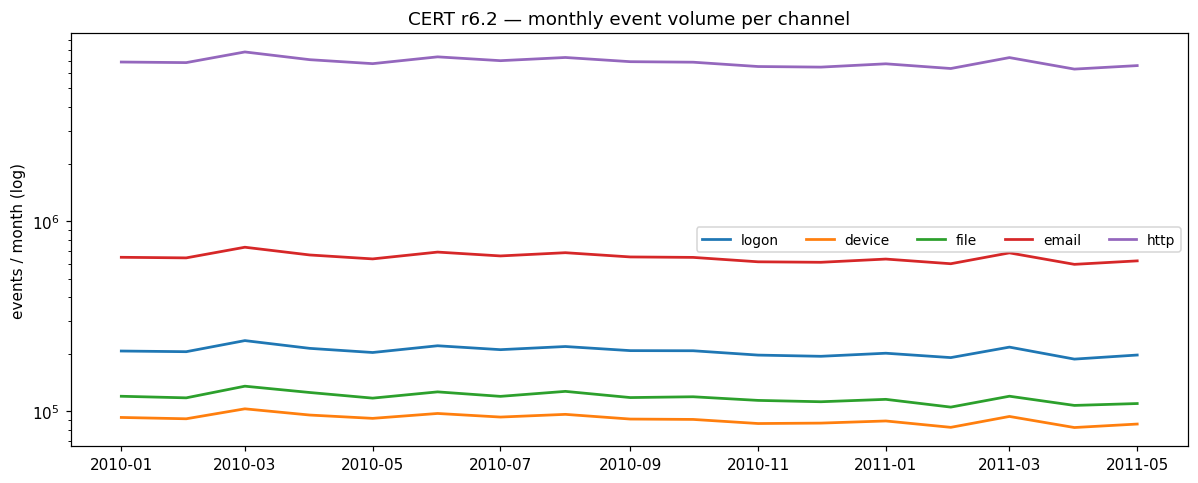

In [7]:
# ============================================================
# 6a. Monthly event volume per channel (clipped at May 2011)
# ============================================================
CUTOFF = pd.Timestamp("2011-06-01")

fig, ax = plt.subplots(figsize=(11, 4.5))
for name, df in channels.items():
    m = (df[df["date"] < CUTOFF]
         .set_index("date").resample("MS").size())
    ax.plot(m.index, m.values, label=name, lw=1.8)
m_http = (http_daily[http_daily["day"] < CUTOFF]
          .set_index("day")["http_count"].resample("MS").sum())
ax.plot(m_http.index, m_http.values, label="http", lw=1.8)
ax.set_yscale("log"); ax.set_ylabel("events / month (log)")
ax.set_title("CERT r6.2 — monthly event volume per channel")
ax.legend(ncol=5, fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_monthly_volume.png", dpi=300)
plt.show()

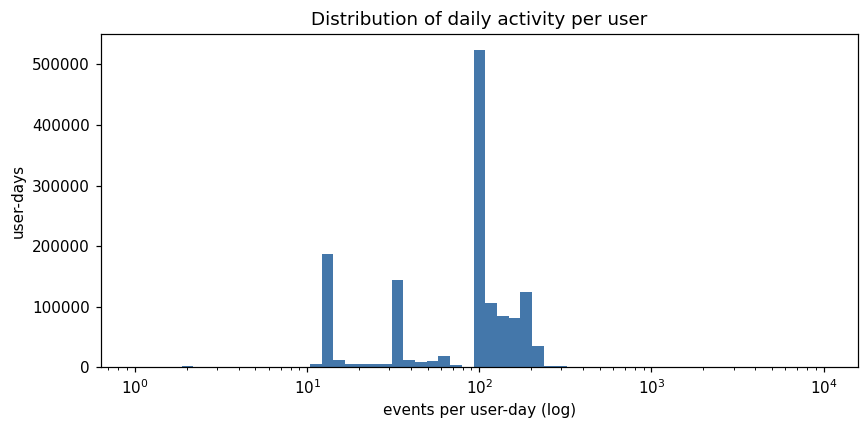

user-day observations: 1,394,010


In [8]:
# ============================================================
# 6b. Daily events per user distribution (all channels)
# ============================================================
per_day_parts = [df.assign(day=df["date"].dt.normalize())
                   .groupby(["user", "day"], observed=True).size()
                   .rename("n").reset_index()
                 for df in channels.values()]
per_day_parts.append(http_daily.rename(columns={"http_count": "n"})
                               [["user", "day", "n"]])
daily = (pd.concat(per_day_parts, ignore_index=True)
           .groupby(["user", "day"], observed=True)["n"].sum())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(daily.values, bins=np.logspace(0, 4, 60), color="#4477AA")
ax.set_xscale("log")
ax.set_xlabel("events per user-day (log)"); ax.set_ylabel("user-days")
ax.set_title("Distribution of daily activity per user")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_userday_activity.png", dpi=300)
plt.show()
print(f"user-day observations: {len(daily):,}")


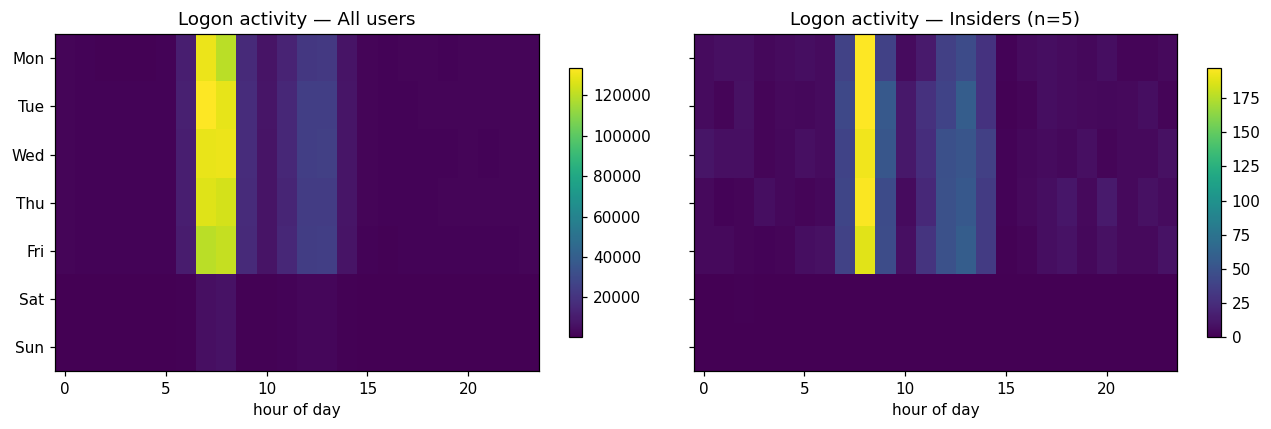

In [9]:
# ============================================================
# 6c. Hour-of-day x weekday heatmaps: all users vs insiders
# ============================================================
lg = logon[logon["activity"].astype(str).str.lower().eq("logon")].copy()
lg["hour"], lg["dow"] = lg["date"].dt.hour, lg["date"].dt.dayofweek
mal = lg[lg["user"].astype(str).isin(MAL_USERS)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, d, title in [(axes[0], lg, "All users"),
                     (axes[1], mal, f"Insiders (n={len(MAL_USERS)})")]:
    pivot = (d.groupby(["dow", "hour"], observed=True).size()
               .unstack(fill_value=0)
               .reindex(index=range(7), columns=range(24), fill_value=0))
    im = ax.imshow(pivot, aspect="auto", cmap="viridis")
    ax.set_title(f"Logon activity — {title}")
    ax.set_xlabel("hour of day")
    ax.set_yticks(range(7))
    ax.set_yticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
    plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_hour_heatmap.png", dpi=300)
plt.show()


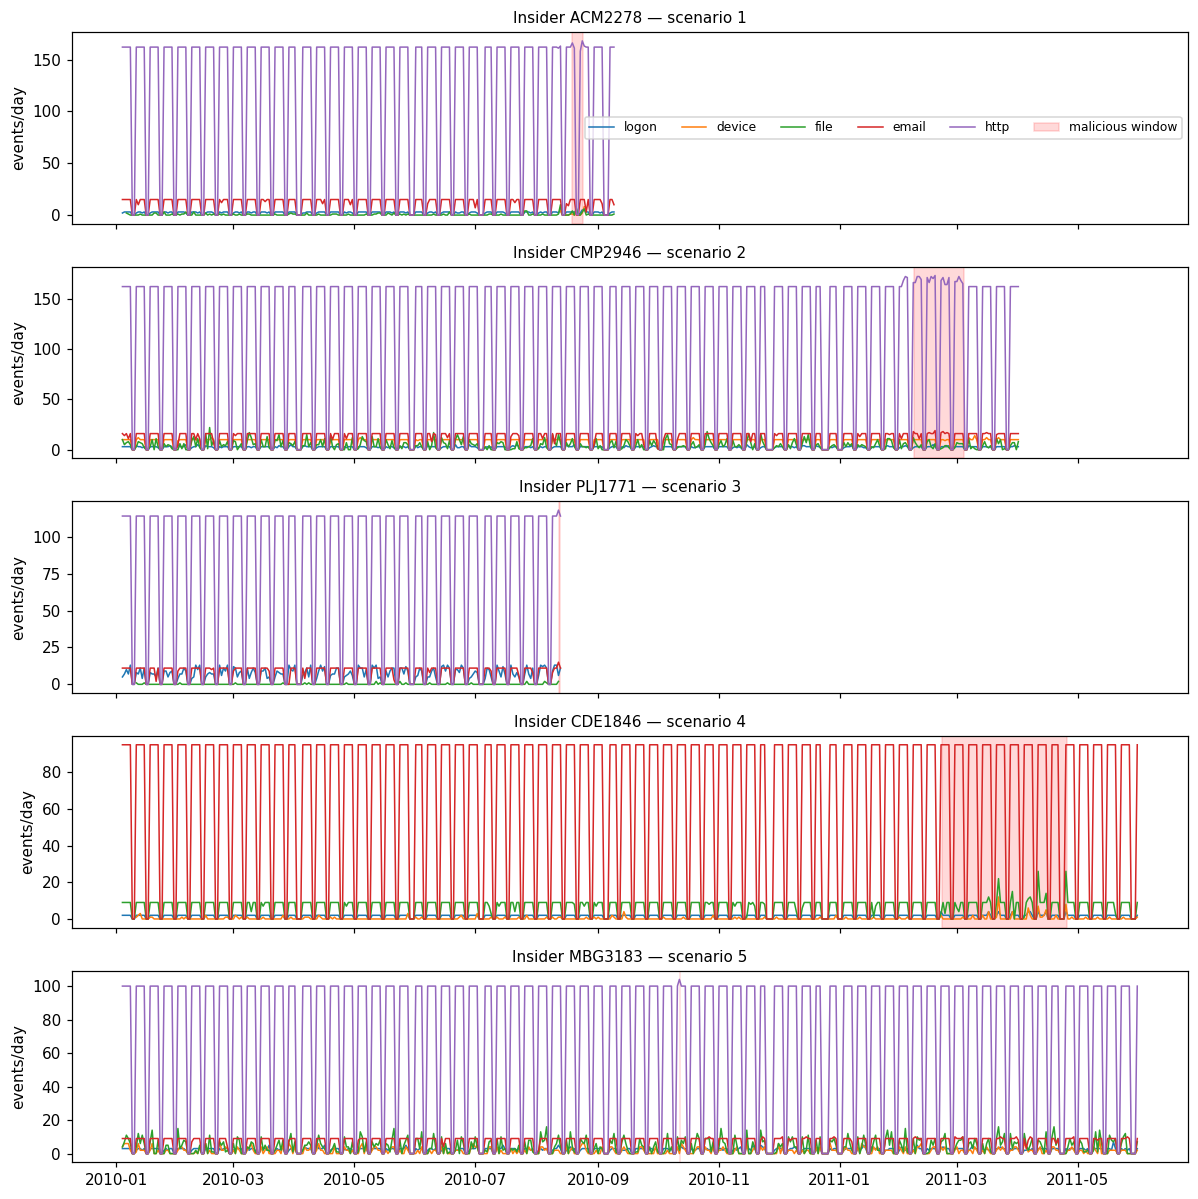

In [10]:
# ============================================================
# 6d. Per-insider timelines with malicious window shading
# ============================================================
start_col = next((c for c in insiders.columns if "start" in c), None)
end_col   = next((c for c in insiders.columns if "end" in c), None)

n = len(insiders)
fig, axes = plt.subplots(n, 1, figsize=(11, 2.2 * n), sharex=True)
axes = np.atleast_1d(axes)

for ax, (_, row) in zip(axes, insiders.iterrows()):
    u = str(row["user"])
    for name, df in channels.items():
        d = df[df["user"].astype(str) == u]
        if len(d):
            s = d.set_index("date").resample("D").size()
            ax.plot(s.index, s.values, lw=1, label=name)
    hu = insider_http[insider_http["user"].astype(str) == u]
    if len(hu):
        s = hu.set_index("date").resample("D").size()
        ax.plot(s.index, s.values, lw=1, label="http")
    if start_col and end_col:
        try:
            ax.axvspan(pd.to_datetime(row[start_col]),
                       pd.to_datetime(row[end_col]),
                       color="red", alpha=0.15, label="malicious window")
        except Exception:
            pass
    ax.set_title(f"Insider {u} — scenario {row.get('scenario', '?')}", fontsize=10)
    ax.set_ylabel("events/day")
axes[0].legend(ncol=7, fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_insider_timelines.png", dpi=300)
plt.show()


## 7. Describe the account-level imbalance

This table counts active user-days belonging to designated insider accounts, including their ordinary activity. It also reports the number of designated insiders and the total user population.

An insider-account day is not necessarily a malicious day. The label-based malicious-user-day counts are constructed separately in Notebook 2. Read the saved `imbalance_table.csv` with that distinction in mind.


In [11]:
# ============================================================
# 7. Imbalance table
# ============================================================
total_ud   = len(daily)
insider_ud = daily[daily.index.get_level_values("user")
                        .astype(str).isin(MAL_USERS)]
imbalance = pd.DataFrame({
    "quantity": ["total user-days", "insider user-days (any activity)",
                 "benign user-days", "insider users", "total users"],
    "value": [total_ud, len(insider_ud), total_ud - len(insider_ud),
              len(MAL_USERS), len(all_users)]})
display(imbalance)
ratio = (total_ud - len(insider_ud)) / max(len(insider_ud), 1)
print(f"benign : insider user-day ratio ≈ {ratio:,.0f} : 1")
print("Day-level MALICIOUS labels (only days containing malicious events)")
print("are built in Notebook 2 from malicious_events.parquet — rarer still.")
imbalance.to_csv(f"{WORK}/imbalance_table.csv", index=False)


,quantity,value
0,total user-days,1394010
1,insider user-days (any activity),1361
2,benign user-days,1392649
3,insider users,5
4,total users,4000


benign : insider user-day ratio ≈ 1,023 : 1
Day-level MALICIOUS labels (only days containing malicious events)
are built in Notebook 2 from malicious_events.parquet — rarer still.


## 8. Check data quality and coverage

The checks report missing values, compare account coverage between the activity logs and LDAP, and show the date range of each channel.

Matching identifiers confirm that records can be linked. They do not establish the correctness of every organisational attribute or outcome label.


In [12]:
# ============================================================
# 8. Data-quality checks
# ============================================================
print("--- Missing values ---")
for name, df in channels.items():
    nulls = df.isna().sum(); nulls = nulls[nulls > 0]
    print(f"{name}: " + (str(nulls.to_dict()) if len(nulls) else "none"))

print("\n--- Identity coverage (logs vs LDAP) ---")
ldap_users = set(ldap["user_id"].astype(str)) if "user_id" in ldap else set()
print("users in logs but never in LDAP:", len(all_users - ldap_users))
print("users in LDAP but never active :", len(ldap_users - all_users))

print("\n--- Timestamp ranges ---")
for name, df in channels.items():
    print(f"{name}: {df['date'].min().date()} -> {df['date'].max().date()}")
print(f"http : {http_daily['day'].min().date()} -> {http_daily['day'].max().date()}")


--- Missing values ---
logon: none
device: none
file: none
email: none

--- Identity coverage (logs vs LDAP) ---
users in logs but never in LDAP: 0
users in LDAP but never active : 0

--- Timestamp ranges ---
logon: 2010-01-02 -> 2011-06-01
device: 2010-01-02 -> 2011-05-31
file: 2010-01-02 -> 2011-05-31
email: 2010-01-02 -> 2011-05-31
http : 2010-01-02 -> 2011-05-31


## 9. Saved files and the next stage

| Output | Use |
|---|---|
| `logon.parquet`, `device.parquet`, `file.parquet`, `email.parquet` | Event-level inputs for Notebook 2. |
| `http_daily.parquet` | Daily HTTP features for Notebook 2. |
| `insider_http_events.parquet` | Descriptive insider-account timelines. |
| `ldap_monthly.parquet` | Organisational records for Notebook 3 and reporting checks. |
| `insiders.parquet`, `malicious_events.parquet` | Answer-derived records for labels, diagnostics and supporting audits; not detector features. |
| `dataset_summary.csv`, `imbalance_table.csv`, `figures/` | Descriptive tables and figures. |

For a reproduction run, retain the saved output version before moving to Notebook 2. Notebook 2 also requires access to the original scenario answer files. Reviewing the saved outputs does not require rerunning this preparation stage.


In [13]:
import os
for f in sorted(os.listdir("/kaggle/working")):
    p = f"/kaggle/working/{f}"
    size = os.path.getsize(p)/1e6 if os.path.isfile(p) else 0
    print(f"{f:40s} {size:10,.1f} MB")

__notebook__.ipynb                              0.7 MB
dataset_summary.csv                             0.0 MB
device.parquet                                 15.3 MB
email.parquet                                 145.3 MB
figures                                         0.0 MB
file.parquet                                   43.0 MB
http_daily.parquet                              2.2 MB
imbalance_table.csv                             0.0 MB
insider_http_events.parquet                     1.7 MB
insiders.parquet                                0.0 MB
ldap_monthly.parquet                            0.7 MB
logon.parquet                                  20.5 MB
malicious_events.parquet                        0.0 MB
